# Strokes Gained vs. Tour Average

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sjsardar/S2PGAGOLF/blob/main/SG_Chart.ipynb)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

url = "https://raw.githubusercontent.com/jordanr-johnson/PGA-Tournament-Python-Project/main/ASA%20All%20PGA%20Raw%20Data%20-%20Tourn%20Level.csv"
df = pd.read_csv(url)
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])
df.shape

(36864, 34)

In [2]:
sg_all = ["sg_ott", "sg_app", "sg_arg", "sg_putt", "sg_total"]
sg_data = df.dropna(subset=sg_all)
player_list = sorted(sg_data["player"].unique())

def show_sg(player):
    p = sg_data[sg_data["player"] == player]
    values = [(p[c] * p["n_rounds"]).sum() / p["n_rounds"].sum() for c in sg_all]
    labels = ["Off the Tee", "Approach", "Around the Green", "Putting", "Total"]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(labels, values, color=["tab:blue" if v >= 0 else "tab:red" for v in values])
    ax.axvline(0, color="black", linewidth=1)
    ax.invert_yaxis()
    for i, v in enumerate(values):
        ax.text(v + (0.02 if v >= 0 else -0.02), i, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right")
    ax.set_xlim(min(values + [0]) - 0.3, max(values) + 0.3)
    ax.set_xlabel("Strokes gained per round (0 = tour average)")
    ax.set_title(f"{player}: Strokes Gained vs. Tour Average ({len(p)} events)")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

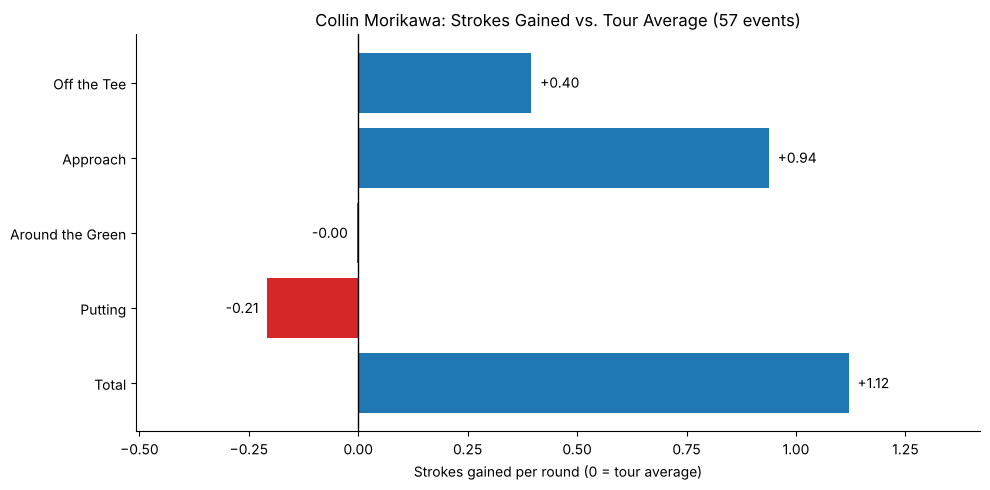

In [3]:
show_sg("Collin Morikawa")

In [4]:
interact(show_sg, player=widgets.Dropdown(options=player_list, value="Collin Morikawa", description="Player"));